In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn nltk joblib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import os

print("Current folder:", os.getcwd())

print("\nFiles available:")
print(os.listdir())

Current folder: C:\Users\ZAIFI\Desktop\internship work\2nd task spam message clasifier

Files available:
['.ipynb_checkpoints', 'dataset', 'read me.md.txt', 'sms+spam+collection.zip', 'spam_classifier_model.pkl', 'Spam_Message_Classifier.ipynb']


In [4]:
import zipfile
import os

zip_path = "sms+spam+collection.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("dataset")

print("Dataset extracted successfully!")

print(os.listdir("dataset"))

Dataset extracted successfully!
['readme', 'SMSSpamCollection']


In [5]:
df = pd.read_csv(
    "dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="latin-1"
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [6]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Messages:")
print(df.duplicated().sum())

print("\nCategory Distribution:")
print(df["label"].value_counts())

Dataset Shape: (5572, 2)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB

Missing Values:
label      0
message    0
dtype: int64

Duplicate Messages:
403

Category Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [7]:
# Remove duplicate messages
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset after removing duplicates:")
print("Total messages:", len(df))

print("\nUpdated category distribution:")
print(df["label"].value_counts())

Dataset after removing duplicates:
Total messages: 5169

Updated category distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


In [8]:
import nltk

nltk.download("stopwords")

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

print("Total English stop words:", len(stop_words))

Total English stop words: 198


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ZAIFI\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [9]:
import re

def preprocess_text(text):

    # 1. Convert to lowercase
    text = text.lower()

    # 2. Tokenization
    words = re.findall(r'\b\w+\b', text)

    # 3. Remove stop words
    words = [
        word for word in words
        if word not in stop_words
    ]

    # 4. Join words
    return " ".join(words)

In [10]:
df["cleaned_message"] = df["message"].apply(preprocess_text)

df[["message", "cleaned_message"]].head(10)

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling 3 week word back like fun ...
6,Even my brother is not like to speak with me. ...,even brother like speak treat like aids patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile 11 months u r entitled update latest co...


In [11]:
# Preserve negation words and contractions
important_words = {
    "not", "no", "nor",
    "don't", "doesn't", "didn't",
    "can't", "couldn't", "shouldn't",
    "wouldn't", "won't",
    "isn't", "aren't", "wasn't", "weren't",
    "haven't", "hasn't", "hadn't"
}

stop_words = set(stopwords.words("english")) - important_words

def preprocess_text(text):
    text = text.lower()

    # Keep apostrophes inside words
    words = re.findall(r"\b[\w']+\b", text)

    words = [
        word for word in words
        if word not in stop_words
    ]

    return " ".join(words)


df["cleaned_message"] = df["message"].apply(preprocess_text)

df[["message", "cleaned_message"]].head(10)

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah don't think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling 3 week's no word back like...
6,Even my brother is not like to speak with me. ...,even brother not like speak treat like aids pa...
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile 11 months u r entitled update latest co...


In [12]:
# Features and target
X = df["cleaned_message"]
y = df["label"]

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: divide temporary data into 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display dataset sizes
print("Training messages:", len(X_train))
print("Validation messages:", len(X_val))
print("Testing messages:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nValidation label distribution:")
print(y_val.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())


Training messages: 3618
Validation messages: 775
Testing messages: 776

Training label distribution:
label
ham     3161
spam     457
Name: count, dtype: int64

Validation label distribution:
label
ham     677
spam     98
Name: count, dtype: int64

Testing label distribution:
label
ham     678
spam     98
Name: count, dtype: int64


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    lowercase=False,
    token_pattern=r"(?u)\b\w+\b"
)

# Learn vocabulary and transform training messages
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and testing messages
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

# Display shapes
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("\nTotal unique words:", len(tfidf.get_feature_names_out()))

Training TF-IDF shape: (3618, 7052)
Validation TF-IDF shape: (775, 7052)
Testing TF-IDF shape: (776, 7052)

Total unique words: 7052


In [14]:
from sklearn.naive_bayes import MultinomialNB

# Create the model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Predict validation messages
nb_predictions = nb_model.predict(X_val_tfidf)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("NAIVE BAYES VALIDATION RESULTS")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_val, nb_predictions))
print("Precision:", precision_score(y_val, nb_predictions, pos_label="spam"))
print("Recall:", recall_score(y_val, nb_predictions, pos_label="spam"))
print("F1 Score:", f1_score(y_val, nb_predictions, pos_label="spam"))

print("\nClassification Report:")
print(classification_report(y_val, nb_predictions))

NAIVE BAYES VALIDATION RESULTS
--------------------------------
Accuracy: 0.9535483870967741
Precision: 1.0
Recall: 0.6326530612244898
F1 Score: 0.775

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       677
        spam       1.00      0.63      0.78        98

    accuracy                           0.95       775
   macro avg       0.97      0.82      0.87       775
weighted avg       0.96      0.95      0.95       775



In [16]:
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict validation messages
lr_predictions = lr_model.predict(X_val_tfidf)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [17]:
print("LOGISTIC REGRESSION VALIDATION RESULTS")
print("--------------------------------------")

print("Accuracy:", accuracy_score(y_val, lr_predictions))
print("Precision:", precision_score(y_val, lr_predictions, pos_label="spam"))
print("Recall:", recall_score(y_val, lr_predictions, pos_label="spam"))
print("F1 Score:", f1_score(y_val, lr_predictions, pos_label="spam"))

print("\nClassification Report:")
print(classification_report(y_val, lr_predictions))

LOGISTIC REGRESSION VALIDATION RESULTS
--------------------------------------
Accuracy: 0.9509677419354838
Precision: 0.9545454545454546
Recall: 0.6428571428571429
F1 Score: 0.7682926829268293

Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       677
        spam       0.95      0.64      0.77        98

    accuracy                           0.95       775
   macro avg       0.95      0.82      0.87       775
weighted avg       0.95      0.95      0.95       775



In [18]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Combine training and validation data
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

# Create the final pipeline
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=False,
        token_pattern=r"(?u)\b\w+\b"
    )),
    ("classifier", MultinomialNB())
])

# Train on combined data
final_model.fit(X_train_final, y_train_final)

# Evaluate on the untouched test data
test_predictions = final_model.predict(X_test)

print("FINAL MODEL: NAIVE BAYES")
print("------------------------")
print("Accuracy:", accuracy_score(y_test, test_predictions))
print("Precision:", precision_score(
    y_test, test_predictions, pos_label="spam"
))
print("Recall:", recall_score(
    y_test, test_predictions, pos_label="spam"
))
print("F1 Score:", f1_score(
    y_test, test_predictions, pos_label="spam"
))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))

FINAL MODEL: NAIVE BAYES
------------------------
Accuracy: 0.9652061855670103
Precision: 1.0
Recall: 0.7244897959183674
F1 Score: 0.8402366863905325

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       678
        spam       1.00      0.72      0.84        98

    accuracy                           0.97       776
   macro avg       0.98      0.86      0.91       776
weighted avg       0.97      0.97      0.96       776



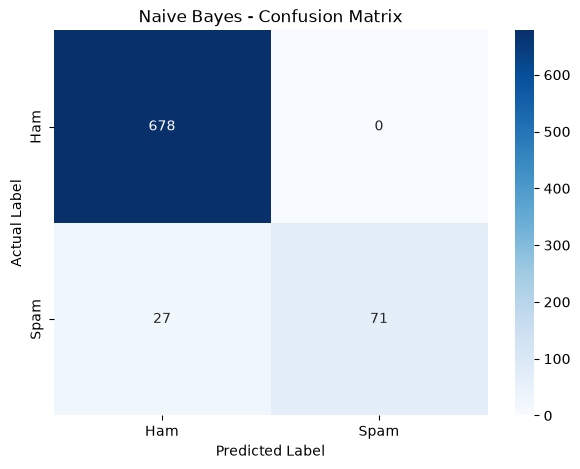

Confusion Matrix:
[[678   0]
 [ 27  71]]


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=["ham", "spam"]
)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Confusion Matrix:")
print(cm)

In [20]:
import joblib

# Save the trained model
joblib.dump(final_model, "spam_classifier_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [21]:
def predict_message(message):

    # Clean the user's message
    cleaned_message = preprocess_text(message)

    # Make prediction
    prediction = final_model.predict([cleaned_message])[0]

    # Get prediction probability
    probabilities = final_model.predict_proba([cleaned_message])[0]

    spam_index = list(final_model.classes_).index("spam")
    spam_probability = probabilities[spam_index] * 100

    print("\nMessage:", message)
    print("Prediction:", prediction.upper())
    print(f"Spam probability: {spam_probability:.2f}%")

# Test your own messages
predict_message("Congratulations! You have won a free iPhone. Click here now!")
predict_message("Hey, are we meeting tomorrow?")


Message: Congratulations! You have won a free iPhone. Click here now!
Prediction: HAM
Spam probability: 41.35%

Message: Hey, are we meeting tomorrow?
Prediction: HAM
Spam probability: 0.60%


In [22]:
message = "Congratulations! You have won a free iPhone. Click here now!"

cleaned = preprocess_text(message)

# Check which words the model knows
vocabulary = final_model.named_steps["tfidf"].vocabulary_

words = cleaned.split()

print("Cleaned message:", cleaned)

print("\nWords known by the model:")
print([word for word in words if word in vocabulary])

print("\nWords unknown to the model:")
print([word for word in words if word not in vocabulary])

print("\nSpam probability:",
      final_model.predict_proba([cleaned])[0][
          list(final_model.classes_).index("spam")
      ])

Cleaned message: congratulations free iphone click

Words known by the model:
['congratulations', 'free', 'iphone', 'click']

Words unknown to the model:
[]

Spam probability: 0.41346693258749767


In [23]:
# Inspect how strongly individual words are associated with spam
nb = final_model.named_steps["classifier"]
vectorizer = final_model.named_steps["tfidf"]

words = ["congratulations", "free", "iphone", "click"]

for word in words:
    index = vectorizer.vocabulary_.get(word)

    if index is not None:
        spam_prob = nb.feature_log_prob_[
            list(nb.classes_).index("spam"), index
        ]

        ham_prob = nb.feature_log_prob_[
            list(nb.classes_).index("ham"), index
        ]

        print(f"\nWord: {word}")
        print(f"Spam log probability: {spam_prob:.4f}")
        print(f"Ham log probability: {ham_prob:.4f}")


Word: congratulations
Spam log probability: -8.0157
Ham log probability: -9.5578

Word: free
Spam log probability: -6.0045
Ham log probability: -7.1320

Word: iphone
Spam log probability: -9.2276
Ham log probability: -9.3490

Word: click
Spam log probability: -8.4641
Ham log probability: -9.2363


In [24]:
from sklearn.metrics import precision_score, recall_score

# Get spam probabilities for validation messages
spam_index = list(final_model.classes_).index("spam")

val_probabilities = final_model.predict_proba(X_val)[:, spam_index]

# Test different thresholds
for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:

    predictions = [
        "spam" if probability >= threshold else "ham"
        for probability in val_probabilities
    ]

    precision = precision_score(
        y_val, predictions, pos_label="spam", zero_division=0
    )

    recall = recall_score(
        y_val, predictions, pos_label="spam"
    )

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")


Threshold: 0.3
Precision: 0.9889
Recall: 0.9082

Threshold: 0.35
Precision: 1.0000
Recall: 0.8673

Threshold: 0.4
Precision: 1.0000
Recall: 0.8367

Threshold: 0.45
Precision: 1.0000
Recall: 0.8061

Threshold: 0.5
Precision: 1.0000
Recall: 0.7551


In [25]:
from sklearn.metrics import precision_score, recall_score

# Use the Naive Bayes model trained ONLY on training data
spam_index = list(nb_model.classes_).index("spam")

# Predict spam probabilities on validation data
val_probabilities = nb_model.predict_proba(X_val_tfidf)[:, spam_index]

# Compare different thresholds
for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:

    predictions = [
        "spam" if probability >= threshold else "ham"
        for probability in val_probabilities
    ]

    precision = precision_score(
        y_val, predictions, pos_label="spam", zero_division=0
    )

    recall = recall_score(
        y_val, predictions, pos_label="spam"
    )

    f1 = f1_score(
        y_val, predictions, pos_label="spam"
    )

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")


Threshold: 0.3
Precision: 0.9863
Recall: 0.7347
F1 Score: 0.8421

Threshold: 0.35
Precision: 1.0000
Recall: 0.7041
F1 Score: 0.8263

Threshold: 0.4
Precision: 1.0000
Recall: 0.6837
F1 Score: 0.8121

Threshold: 0.45
Precision: 1.0000
Recall: 0.6633
F1 Score: 0.7975

Threshold: 0.5
Precision: 1.0000
Recall: 0.6327
F1 Score: 0.7750


In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Get spam probabilities on test data
spam_index = list(final_model.classes_).index("spam")

test_probabilities = final_model.predict_proba(X_test)[:, spam_index]

# Apply selected threshold
THRESHOLD = 0.30

threshold_predictions = [
    "spam" if probability >= THRESHOLD else "ham"
    for probability in test_probabilities
]

# Evaluate
print("FINAL MODEL - THRESHOLD 0.30")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, threshold_predictions))
print("Precision:", precision_score(
    y_test, threshold_predictions, pos_label="spam"
))
print("Recall:", recall_score(
    y_test, threshold_predictions, pos_label="spam"
))
print("F1 Score:", f1_score(
    y_test, threshold_predictions, pos_label="spam"
))

print("\nClassification Report:")
print(classification_report(y_test, threshold_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    threshold_predictions,
    labels=["ham", "spam"]
))

FINAL MODEL - THRESHOLD 0.30
--------------------------------
Accuracy: 0.979381443298969
Precision: 0.9880952380952381
Recall: 0.8469387755102041
F1 Score: 0.9120879120879121

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       678
        spam       0.99      0.85      0.91        98

    accuracy                           0.98       776
   macro avg       0.98      0.92      0.95       776
weighted avg       0.98      0.98      0.98       776


Confusion Matrix:
[[677   1]
 [ 15  83]]


In [27]:
THRESHOLD = 0.30

def predict_message(message):

    # Preprocess the input
    cleaned_message = preprocess_text(message)

    # Calculate spam probability
    probabilities = final_model.predict_proba([cleaned_message])[0]

    spam_index = list(final_model.classes_).index("spam")
    spam_probability = probabilities[spam_index]

    # Apply custom threshold
    if spam_probability >= THRESHOLD:
        prediction = "SPAM"
    else:
        prediction = "HAM"

    print("\nOriginal Message:", message)
    print("Cleaned Message:", cleaned_message)
    print("Prediction:", prediction)
    print(f"Spam Probability: {spam_probability * 100:.2f}%")
    print("Decision Threshold:", THRESHOLD)

In [28]:
predict_message("Congratulations! You have won a free iPhone. Click here now!")

predict_message("Hey, are we meeting tomorrow?")

predict_message("URGENT! You have won a cash prize. Call now to claim.")


Original Message: Congratulations! You have won a free iPhone. Click here now!
Cleaned Message: congratulations free iphone click
Prediction: SPAM
Spam Probability: 41.35%
Decision Threshold: 0.3

Original Message: Hey, are we meeting tomorrow?
Cleaned Message: hey meeting tomorrow
Prediction: HAM
Spam Probability: 0.60%
Decision Threshold: 0.3

Original Message: URGENT! You have won a cash prize. Call now to claim.
Cleaned Message: urgent cash prize call claim
Prediction: SPAM
Spam Probability: 95.27%
Decision Threshold: 0.3


In [29]:
import joblib

model_artifact = {
    "model": final_model,
    "threshold": THRESHOLD,
    "class_names": ["ham", "spam"]
}

joblib.dump(model_artifact, "spam_classifier_model.pkl")

print("Final model and threshold saved successfully!")

Final model and threshold saved successfully!


In [30]:
model_artifact = {
    "model": final_model,
    "threshold": THRESHOLD,
    "class_names": ["ham", "spam"],
    "stop_words": stop_words
}

joblib.dump(model_artifact, "spam_classifier_model.pkl")

print("Complete model artifact saved successfully!")

Complete model artifact saved successfully!


In [31]:
import joblib

loaded_artifact = joblib.load("spam_classifier_model.pkl")

loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]
loaded_stop_words = loaded_artifact["stop_words"]

print("Model loaded successfully!")
print("Threshold:", loaded_threshold)
print("Classes:", loaded_artifact["class_names"])
print("Number of stop words:", len(loaded_stop_words))

Model loaded successfully!
Threshold: 0.3
Classes: ['ham', 'spam']
Number of stop words: 181


In [32]:
import re

def predict_new_message(message):
    # Preprocessing
    text = message.lower()
    words = re.findall(r"\b[\w']+\b", text)

    words = [
        word for word in words
        if word not in loaded_stop_words
    ]

    cleaned_message = " ".join(words)

    # Prediction using loaded model
    probabilities = loaded_model.predict_proba([cleaned_message])[0]

    spam_index = list(loaded_model.classes_).index("spam")
    spam_probability = probabilities[spam_index]

    if spam_probability >= loaded_threshold:
        prediction = "SPAM"
    else:
        prediction = "HAM"

    print("Original Message:", message)
    print("Cleaned Message:", cleaned_message)
    print("Prediction:", prediction)
    print(f"Spam Probability: {spam_probability * 100:.2f}%")
    print("-" * 40)


predict_new_message("Congratulations! You won a free iPhone. Click here!")
predict_new_message("Hey, are we meeting tomorrow?")

Original Message: Congratulations! You won a free iPhone. Click here!
Cleaned Message: congratulations free iphone click
Prediction: SPAM
Spam Probability: 41.35%
----------------------------------------
Original Message: Hey, are we meeting tomorrow?
Cleaned Message: hey meeting tomorrow
Prediction: HAM
Spam Probability: 0.60%
----------------------------------------
